## Exercise 12.3 (Classification using aeon’s Time Series Forest Classifier)  

- Load the UWaveGestureLibrary data set.
- Use aeon’s TimeSeriesForestClassifier to classify the data set.
- Are you able to achieve better results than with the previous algorithms?

# 1 Load the UWaveGestureLibrary data set. 

In [1]:
from sktime.datasets import load_UCR_UEA_dataset

# Datensatz und Format entsprechend dem Hinweis im Skript festlegen.
ds_name = "UWaveGestureLibrary"
ret_type = "numpy3d"

# Trainingsdaten laden. Die Liste erlaubt unterschiedlich lange Zeitreihen.
X_train, y_train = load_UCR_UEA_dataset(
    name=ds_name,
    split="train",
    return_type=ret_type,
)

# Testdaten im gleichen Format laden.
X_test, y_test = load_UCR_UEA_dataset(
    name=ds_name,
    split="test",
    return_type=ret_type,
)

print("Anzahl Trainingszeitreihen:", len(X_train))
print("Anzahl Testzeitreihen:", len(X_test))

Anzahl Trainingszeitreihen: 120
Anzahl Testzeitreihen: 320


# 2 Use aeon’s TimeSeriesForestClassifier to classify the data set.

Genauigkeit auf den Testdaten: 86.56%
Laufzeit für Training und Vorhersage: 9.65 Sekunden.


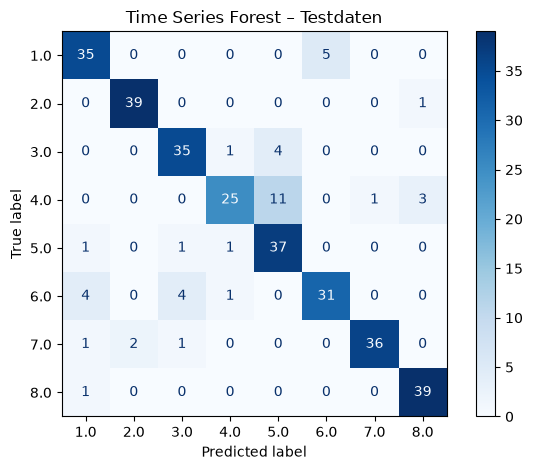

In [2]:
import time
import matplotlib.pyplot as plt
from aeon.classification.interval_based import TimeSeriesForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 1. Time Series Forest mit 200 Entscheidungsbäumen erstellen.
# 200 Bäume entsprechen dem Standardwert der aeon-Implementierung.
tsf = TimeSeriesForestClassifier(
    n_estimators=200,
    random_state=42
)

# 2. Mit den Trainingszeitreihen und ihren Klassen trainieren.
start_time = time.time()

tsf.fit(X_train, y_train)

# 3. Klassen der Testzeitreihen vorhersagen.
y_pred_tsf = tsf.predict(X_test)

duration_tsf = time.time() - start_time

# 4. Vorhersagen mit den tatsächlichen Testklassen vergleichen.
accuracy_tsf = accuracy_score(y_test, y_pred_tsf)

print(f"Genauigkeit auf den Testdaten: {accuracy_tsf:.2%}")
print(f"Laufzeit für Training und Vorhersage: {duration_tsf:.2f} Sekunden.")

# 5. Richtige Zuordnungen und Verwechslungen darstellen.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tsf,
    cmap="Blues"
)

plt.title("Time Series Forest – Testdaten")
plt.tight_layout()
plt.show()

# 3 Are you able to achieve better results than with the previous algorithms?

Der Time Series Forest erkennt 277 von 320 Testgesten korrekt und erreicht eine Genauigkeit von 86,56 %. Damit liegt er über dem CNN mit 79,69 %, aber unter kNN mit DTW mit 90,31 %. Training und Vorhersage benötigen zusammen 9,65 Sekunden.

Die Konfusionsmatrix zeigt weiterhin Schwierigkeiten bei Klasse 4: Elf ihrer 40 Beispiele werden als Klasse 5 erkannt. Klasse 5 wird dagegen mit 37 richtigen Zuordnungen besser erkannt als bei den beiden vorherigen Verfahren.

In diesem Versuch verbessert der Time Series Forest somit das CNN-Ergebnis. Das beste Gesamtergebnis liefert weiterhin kNN mit DTW.

ipynb exportiert als html mit:

uv run jupyter nbconvert --to html "Tasks/12 Self study - Session 3/Exercise_12.3.ipynb"